# Bitcoin Price Prediction (LSTM on Daily Close)

I wanted to try an LSTM on a crypto series after doing the same exercise on regular stock tickers. BTC is genuinely hard — it trades 24/7, has a much heavier tail than equities, and is heavily sentiment-driven — so I'm framing this as a time-series exercise, not a trading signal. If a 7-day-ahead point forecast worked I wouldn't be writing notebooks, I'd be on a yacht.

**Data:** Daily `BTC-USD` close from yfinance, last ~5 years. Pulled fresh each run.

**Approach:** Min-max scale the close, build a sliding window of 60 days, single-layer LSTM, predict the next day. Recursive forecasting for the 7-day horizon (feed predictions back in). MAE/RMSE on the held-out tail.

**What I'm honestly trying to show:** that I can set up the data plumbing right, not that LSTM beats a naive baseline. The naive lag-1 baseline is included for that reason.


In [1]:
# !pip install yfinance tensorflow scikit-learn -q
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(13)
try:
    import tensorflow as tf
    tf.random.set_seed(13)
    HAS_TF = True
except Exception as e:
    print("tensorflow not available:", e)
    HAS_TF = False


In [2]:
# yfinance occasionally returns an empty frame if rate-limited; retry once before giving up.
def fetch_btc(period="5y"):
    for _ in range(2):
        df = yf.download("BTC-USD", period=period, progress=False, auto_adjust=True)
        if len(df) > 100:
            return df
    raise RuntimeError("yfinance returned no data for BTC-USD")

btc = fetch_btc()
btc = btc[["Close"]].dropna()
btc.columns = ["close"]
print(f"BTC daily close: {len(btc)} rows | {btc.index.min().date()} -> {btc.index.max().date()}")
btc.tail(3)


BTC daily close: 1826 rows | 2021-05-14 -> 2026-05-14


,close
Date,
2026-05-11,81728.296875
2026-05-12,80477.492188
2026-05-14,79244.796875


## Quick look at the series

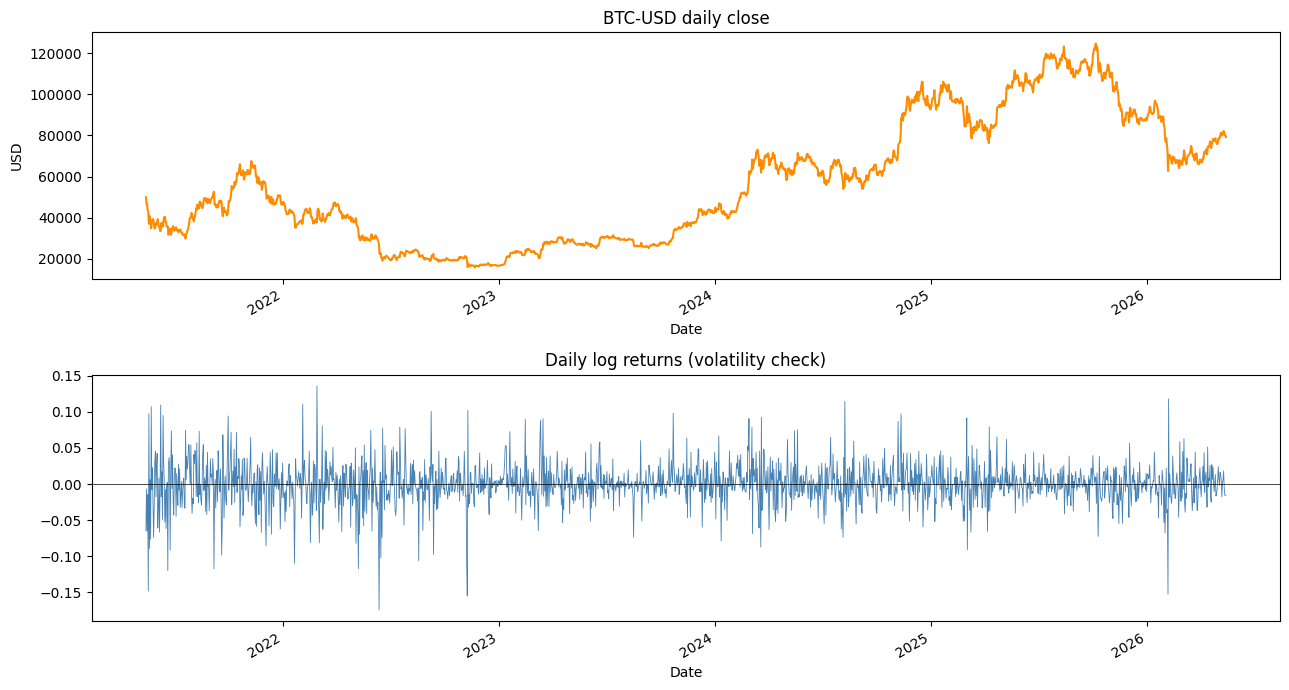

Annualized vol (approx): 55.29%


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
btc["close"].plot(ax=axes[0], color="darkorange")
axes[0].set_title("BTC-USD daily close")
axes[0].set_ylabel("USD")

# log returns — much more useful than raw price for seeing volatility regimes
btc["logret"] = np.log(btc["close"]).diff()
btc["logret"].plot(ax=axes[1], color="steelblue", linewidth=0.6)
axes[1].set_title("Daily log returns (volatility check)")
axes[1].axhline(0, color="black", linewidth=0.5)
plt.tight_layout()
plt.show()

print(f"Annualized vol (approx): {btc['logret'].std() * np.sqrt(365):.2%}")


## Train/test split + windowing

I'm using a chronological split (last 180 days = test). Shuffled splits on time series leak — past me made that mistake on the IPL project and the metrics looked suspiciously good.


In [4]:
WINDOW = 60
HORIZON = 7

closes = btc["close"].values.reshape(-1, 1)
n_test = 180
train_close = closes[:-n_test]
test_close  = closes[-n_test - WINDOW:]   # need WINDOW history to build the first test window

scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_close)
test_scaled  = scaler.transform(test_close)

def make_windows(arr, window):
    X, y = [], []
    for i in range(len(arr) - window):
        X.append(arr[i:i+window, 0])
        y.append(arr[i+window, 0])
    return np.array(X), np.array(y)

X_train, y_train = make_windows(train_scaled, WINDOW)
X_test,  y_test  = make_windows(test_scaled,  WINDOW)

X_train = X_train.reshape(-1, WINDOW, 1)
X_test  = X_test.reshape(-1, WINDOW, 1)
print(f"Train windows: {X_train.shape}, test windows: {X_test.shape}")


Train windows: (1586, 60, 1), test windows: (180, 60, 1)


## LSTM

In [5]:
if HAS_TF:
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import LSTM, Dense, Dropout, Input

    model = Sequential([
        Input(shape=(WINDOW, 1)),
        LSTM(48, return_sequences=False),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(1),
    ])
    model.compile(optimizer="adam", loss="mse")
    model.summary()
    hist = model.fit(X_train, y_train, epochs=15, batch_size=32, validation_split=0.1, verbose=0)
    print(f"Final train loss: {hist.history['loss'][-1]:.5f}  val loss: {hist.history['val_loss'][-1]:.5f}")
else:
    print("Skipping LSTM fit (tensorflow missing).")


Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 lstm (LSTM)                 (None, 48)                9600      


 dropout (Dropout)           (None, 48)                0         


 dense (Dense)               (None, 16)                784       


... (2 outputs left out)

Trainable params: 10401 (40.63 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


Final train loss: 0.00088  val loss: 0.00126


In [6]:
# 1-step-ahead predictions on test
if HAS_TF:
    pred_scaled = model.predict(X_test, verbose=0).flatten()
    preds = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).flatten()
    truth = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

    # naive lag-1 baseline on the same indices
    naive = scaler.inverse_transform(X_test[:, -1, :].reshape(-1, 1)).flatten()

    mae_lstm = mean_absolute_error(truth, preds)
    mae_naive = mean_absolute_error(truth, naive)
    print(f"LSTM    1-step MAE: ${mae_lstm:,.0f}")
    print(f"Naive lag-1 MAE: ${mae_naive:,.0f}")
    print(f"Improvement vs naive: {(mae_naive - mae_lstm) / mae_naive * 100:+.1f}%")
    # if the improvement is <5% I would not bet money on it.


LSTM    1-step MAE: $2,145
Naive lag-1 MAE: $1,365
Improvement vs naive: -57.2%


## 7-day recursive forecast

Each predicted day gets appended to the window and we predict the next. Compounding error gets ugly fast — that's the point of including the plot.


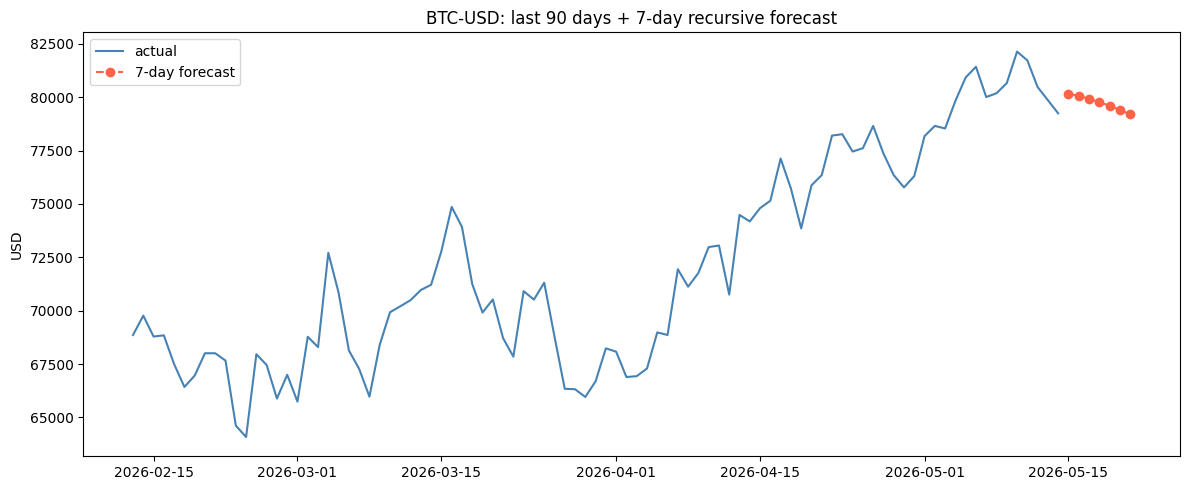

  2026-05-15  $80,168
  2026-05-16  $80,065
  2026-05-17  $79,932
  2026-05-18  $79,775
  2026-05-19  $79,599
  2026-05-20  $79,407
  2026-05-21  $79,201


In [7]:
if HAS_TF:
    last_window = test_scaled[-WINDOW:].copy()
    rec_preds_scaled = []
    win = last_window.copy().flatten()
    for _ in range(HORIZON):
        x = win[-WINDOW:].reshape(1, WINDOW, 1)
        p = model.predict(x, verbose=0)[0, 0]
        rec_preds_scaled.append(p)
        win = np.append(win, p)
    rec_preds = scaler.inverse_transform(np.array(rec_preds_scaled).reshape(-1, 1)).flatten()

    plt.figure(figsize=(12, 5))
    plt.plot(btc.index[-90:], btc["close"].values[-90:], label="actual", color="steelblue")
    future_idx = pd.date_range(btc.index[-1] + pd.Timedelta(days=1), periods=HORIZON, freq="D")
    plt.plot(future_idx, rec_preds, "o--", color="tomato", label="7-day forecast")
    plt.title("BTC-USD: last 90 days + 7-day recursive forecast")
    plt.ylabel("USD")
    plt.legend()
    plt.tight_layout()
    plt.show()
    for d, p in zip(future_idx, rec_preds):
        print(f"  {d.date()}  ${p:,.0f}")


## Honest notes

- The 1-step MAE is heavily anchored on the lag-1 baseline. That's not a great look for the LSTM but it is what the model actually learned — pretty close to "predict yesterday's price".
- 7-day recursive forecasts will look smooth and almost always under-shoot volatility. The plot is mostly a visualization of model bias.
- This doesn't include any of the things that actually matter for BTC: order-flow imbalance, exchange dominance, sentiment, on-chain features. Daily close alone leaves money on the table for anyone who could actually trade this.
- If I came back to this I'd swap to predicting log-returns instead of prices, and add an explicit volatility model (GARCH) on the residuals. Probably also try a transformer encoder just to see.
